In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
house = pd.read_csv("C:/Users/shrid/Downloads/House_Price_dataset (1).csv")

In [4]:
house.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,yes,no,no,no,yes,2.0,yes,furnished
1,12250000,8960,4.0,4.0,4.0,yes,no,no,no,yes,3.0,no,furnished
2,12250000,9960,3.0,2.0,2.0,yes,no,yes,no,no,2.0,yes,semi-furnished
3,12215000,7500,4.0,2.0,2.0,yes,no,yes,no,yes,3.0,yes,furnished
4,11410000,7420,4.0,1.0,2.0,yes,yes,yes,no,yes,2.0,no,furnished


In [5]:
house.shape

(545, 13)

In [6]:
house.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   price             545 non-null    int64  
 1   area              545 non-null    int64  
 2   bedrooms          540 non-null    float64
 3   bathrooms         540 non-null    float64
 4   stories           543 non-null    float64
 5   mainroad          545 non-null    object 
 6   guestroom         545 non-null    object 
 7   basement          545 non-null    object 
 8   hotwaterheating   545 non-null    object 
 9   airconditioning   545 non-null    object 
 10  parking           541 non-null    float64
 11  prefarea          545 non-null    object 
 12  furnishingstatus  545 non-null    object 
dtypes: float64(4), int64(2), object(7)
memory usage: 55.5+ KB


In [7]:
house.isnull().sum()

price               0
area                0
bedrooms            5
bathrooms           5
stories             2
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             4
prefarea            0
furnishingstatus    0
dtype: int64

In [8]:
house.duplicated().sum()

np.int64(0)

In [9]:
house["bedrooms"] = house["bedrooms"].fillna(house["bedrooms"].median())
house["bathrooms"] = house["bathrooms"].fillna(house["bathrooms"].median())
house["stories"] = house["stories"].fillna(house["stories"].median())
house["parking"] = house["parking"].fillna(house["parking"].median())

In [10]:
house.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [11]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
house["mainroad"] = le.fit_transform(house["mainroad"])
house["guestroom"] = le.fit_transform(house["guestroom"])
house["basement"] = le.fit_transform(house["basement"])
house["hotwaterheating"] = le.fit_transform(house["hotwaterheating"])
house["airconditioning"] = le.fit_transform(house["airconditioning"])
house["prefarea"] = le.fit_transform(house["prefarea"])
house["furnishingstatus"] = le.fit_transform(house["furnishingstatus"])

house.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,1,0,0,0,1,2.0,1,0
1,12250000,8960,4.0,4.0,4.0,1,0,0,0,1,3.0,0,0
2,12250000,9960,3.0,2.0,2.0,1,0,1,0,0,2.0,1,1
3,12215000,7500,4.0,2.0,2.0,1,0,1,0,1,3.0,1,0
4,11410000,7420,4.0,1.0,2.0,1,1,1,0,1,2.0,0,0


In [12]:
x = house.drop(columns=["price"])
y = house["price"]

In [13]:
x

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,7420,4.0,2.0,3.0,1,0,0,0,1,2.0,1,0
1,8960,4.0,4.0,4.0,1,0,0,0,1,3.0,0,0
2,9960,3.0,2.0,2.0,1,0,1,0,0,2.0,1,1
3,7500,4.0,2.0,2.0,1,0,1,0,1,3.0,1,0
4,7420,4.0,1.0,2.0,1,1,1,0,1,2.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
540,3000,2.0,1.0,1.0,1,0,1,0,0,2.0,0,2
541,2400,3.0,1.0,1.0,0,0,0,0,0,0.0,0,1
542,3620,2.0,1.0,1.0,1,0,0,0,0,0.0,0,2
543,2910,3.0,1.0,1.0,0,0,0,0,0,0.0,0,0


In [14]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [16]:
from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()
model_lr.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [18]:
y_pred = model_lr.predict(x_test)

In [19]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [22]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("linear MSE:", mse)
print("linear MAE:", mae)
print("linear R2 Score:", r2)

linear MSE: 1762261595678.3093
linear MAE: 974800.4763575833
linear R2 Score: 0.6513528332210878


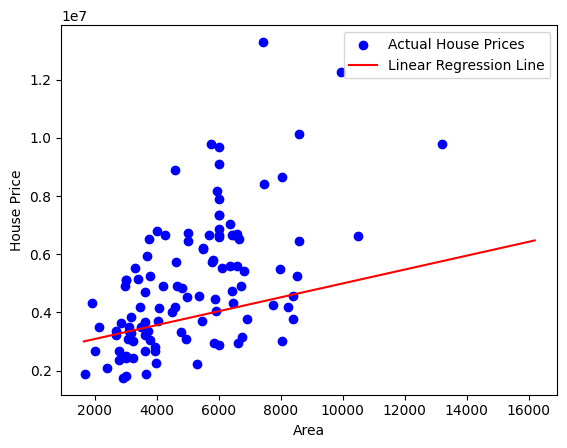

In [36]:
area_values = np.linspace(x_train["area"].min(),x_train["area"].max(),100)

line_data = pd.DataFrame([x_train.median()] * 100,columns=x_train.columns)
line_data["area"] = area_values
line_pred = model_lr.predict(line_data)

plt.scatter(x_test["area"], y_test,color="blue", label="Actual House Prices")
plt.plot(area_values, line_pred,color="red", label="Linear Regression Line")

plt.xlabel("Area")
plt.ylabel("House Price")
plt.legend()

In [22]:
#degree = int(input("Enter polynomial degree :")

Enter polynomial degree :  3


In [38]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

In [39]:
x_train_poly = poly.fit_transform(x_train)
x_test_poly = poly.transform(x_test)

In [42]:
pr_model = LinearRegression()
pr_model.fit(x_train_poly, y_train)
y_pred_poly = pr_model.predict(x_test_poly)

In [44]:
p_mse = mean_squared_error(y_test, y_pred_poly)
p_mae = mean_absolute_error(y_test, y_pred_poly)
p_r2 = r2_score(y_test, y_pred_poly)

In [45]:
print("Polynomial MSE:", p_mse)
print("Polynomial MAE:", p_mae)
print("Polynomial R2 Score:", p_r2)

Polynomial MSE: 1731352943015.4014
Polynomial MAE: 997029.3872762134
Polynomial R2 Score: 0.6574678244382279


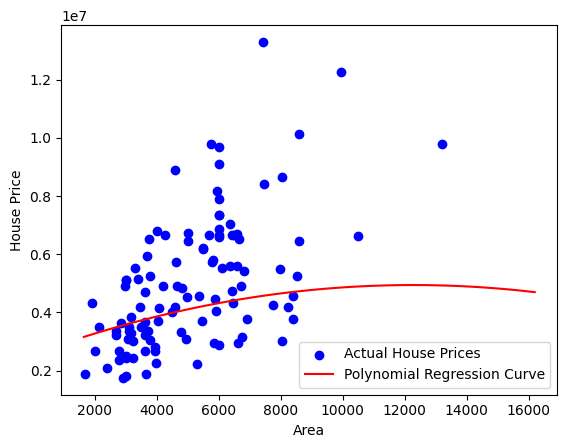

In [48]:
area_values = np.linspace(x_train["area"].min(),x_train["area"].max(),100)

poly_line_data = pd.DataFrame([x_train.median()] * 100,columns=x_train.columns)
poly_line_data["area"] = area_values
poly_line_pred = pr_model.predict(poly.transform(poly_line_data))

plt.scatter(x_test["area"], y_test,color="blue", label="Actual House Prices")
plt.plot(area_values, poly_line_pred,color="red", label="Polynomial Regression Curve")

plt.xlabel("Area")
plt.ylabel("House Price")
plt.legend()

In [50]:
area = float(input("Enter area: "))
bedrooms = int(input("Enter number of bedrooms: "))
bathrooms = int(input("Enter number of bathrooms: "))
stories = int(input("Enter number of stories: "))

Enter area:  6000
Enter number of bedrooms:  3
Enter number of bathrooms:  2
Enter number of stories:  2


In [51]:
mainroad = input("Main road available? (y/n): ").lower()
guestroom = input("Guest room available? (y/n): ").lower()
basement = input("Basement available? (y/n): ").lower()
hotwaterheating = input("Hot water heating available? (y/n): ").lower()
airconditioning = input("Air conditioning available? (y/n): ").lower()
parking = int(input("Enter number of parking spaces: "))
prefarea = input("Preferred area? (y/n): ").lower()
furnishingstatus = input("Furnishing status (f=furnished/s=semi-furnished/u=unfurnished): ").lower()


Main road available? (y/n):  y
Guest room available? (y/n):  n
Basement available? (y/n):  y
Hot water heating available? (y/n):  n
Air conditioning available? (y/n):  y
Enter number of parking spaces:  1
Preferred area? (y/n):  y
Furnishing status (f=furnished/s=semi-furnished/u=unfurnished):  s


In [52]:
if mainroad == "y":
    mainroad = 1
else:
    mainroad = 0
if guestroom == "y":
    guestroom = 1
else:
    guestroom = 0
if basement == "y":
    basement = 1
else:
    basement = 0
if hotwaterheating == "y":
    hotwaterheating = 1
else:
    hotwaterheating = 0
if airconditioning == "y":
    airconditioning = 1
else:
    airconditioning = 0
if prefarea == "y":
    prefarea = 1
else:
    prefarea = 0

if furnishingstatus == "f":
    furnishingstatus = 0
elif furnishingstatus == "s":
    furnishingstatus = 1
else:
    furnishingstatus = 2

In [54]:
user_data = pd.DataFrame({
    "area": [area],
    "bedrooms": [bedrooms],
    "bathrooms": [bathrooms],
    "stories": [stories],
    "mainroad": [mainroad],
    "guestroom": [guestroom],
    "basement": [basement],
    "hotwaterheating": [hotwaterheating],
    "airconditioning": [airconditioning],
    "parking": [parking],
    "prefarea": [prefarea],
    "furnishingstatus": [furnishingstatus]
})
user_data=user_data[x.columns]

In [55]:
user_data

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,6000.0,3,2,2,1,0,1,0,1,1,1,1


In [56]:
linear_prediction = model_lr.predict(user_data)[0]

user_data_poly = poly.transform(user_data)
polynomial_prediction = pr_model.predict(user_data_poly)[0]

print("House Price Predictions")
print("Linear Regression Prediction:", linear_prediction)
print("Polynomial Regression Prediction:", polynomial_prediction)

House Price Predictions
Linear Regression Prediction: 7113040.494490694
Polynomial Regression Prediction: 7871266.303981678
